
<div style="background:#F7F3EA; padding:45px 35px; border:1px solid #D8C5A0; border-radius:10px; color:#174D38;">

<p style="font-size:12px; letter-spacing:3px; font-weight:bold;">
RIYADH SPATIAL ATLAS · 2026
</p>

<hr style="border:0; border-top:1px solid #C5A45A; margin:25px 0;">

<h1 style="font-family:Georgia,serif; font-size:42px; line-height:1.15; font-weight:normal; color:#174D38;">
Where the Desert<br>
Meets the City
</h1>

<p style="font-family:Georgia,serif; font-size:17px; line-height:1.7;">
Mapping Riyadh's Urban–Rural Transition<br>
Through Building Footprints
</p>

<div style="height:35px;"></div>

<p style="font-size:12px; letter-spacing:1.5px; color:#A1814D;">
30-DAY MAP CHALLENGE · DAY 09
</p>

<p style="font-family:Georgia,serif; font-size:14px; line-height:1.8;">
<strong>Alhaylam Alajmi</strong><br>
Master of Urban Spatial Analytics<br>
University of Pennsylvania
</p>

<p style="text-align:right; font-size:12px; color:#A1814D;">
الرياض | المملكة العربية السعودية
</p>

</div>



<div style="background:#FBF8F1; padding:30px; border:1px solid #D8C5A0; border-radius:10px; color:#174D38; font-family:Georgia,serif;">

<p style="font-size:12px; letter-spacing:2px; color:#A1814D;">
01 / THE CONTEXT
</p>

<h2 style="font-weight:normal; font-size:28px; color:#174D38;">
Understanding Riyadh's Urban Edge
</h2>

<p style="font-size:15px; line-height:1.9;">
Riyadh has experienced substantial urban development, transforming parts of its surrounding landscape into an increasingly complex metropolitan environment. The spatial distribution of buildings provides a useful perspective for examining the city's urban form, particularly where concentrated development transitions into sparsely built and undeveloped areas.
</p>

<p style="font-size:15px; line-height:1.9;">
This project uses geospatial building footprint data to examine variations in built-up coverage across Riyadh. By combining building geometry with street network data, the analysis illustrates differences in urban intensity and spatial structure within a defined study area.
</p>

<div style="background:#F1EBDD; padding:20px; border-radius:6px; margin-top:25px;">

<p style="font-size:12px; letter-spacing:1.5px; color:#A1814D;">
RESEARCH QUESTION
</p>

<p style="font-size:17px; line-height:1.7;">
How does building footprint coverage vary across Riyadh, and what spatial patterns distinguish its densely built urban core from its less-developed peripheral areas?
</p>

</div>

<p style="font-size:11px; font-style:italic; color:#A1814D; margin-top:25px;">
30-Day Map Challenge 2026 | Day 09: Urban–Rural
</p>

</div>


In [1]:

from pathlib import Path
import sys
import geopandas as gpd

# ============================================================
# 01 | PROJECT CONFIGURATION
# ============================================================

project_root = Path.cwd().resolve().parents[1]

data_dir = (
    project_root
    / "data"
    / "day09_building_footprints"
)

maps_dir = (
    project_root
    / "maps"
    / "day09_urban_rural"
)

maps_dir.mkdir(parents=True, exist_ok=True)

CRS_GEOGRAPHIC = "EPSG:4326"
CRS_PROJECTED = "EPSG:32638"

print("Python:", sys.version.split()[0])
print("GeoPandas:", gpd.__version__)
print("Project:", project_root)
print("Data directory exists:", data_dir.exists())
print("Maps directory exists:", maps_dir.exists())
print("Projected CRS:", CRS_PROJECTED)


Python: 3.12.15
GeoPandas: 1.2.0
Project: C:\Users\Alhaylam Alajmi\Desktop
Data directory exists: False
Maps directory exists: True
Projected CRS: EPSG:32638


In [3]:

from pathlib import Path
import sys
import geopandas as gpd

# ============================================================
# 01 | PROJECT CONFIGURATION
# ============================================================

project_root = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop"
    r"\Riyadh-30DayMapChallenge-2026"
    r"\Riyadh-30DayMapChallenge-2026"
)

data_dir = (
    project_root
    / "data"
    / "day09_building_footprints"
)

maps_dir = (
    project_root
    / "maps"
    / "day09_urban_rural"
)

if not project_root.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {project_root}"
    )

if not data_dir.is_dir():
    raise FileNotFoundError(
        f"Data folder not found: {data_dir}"
    )

maps_dir.mkdir(parents=True, exist_ok=True)

CRS_GEOGRAPHIC = "EPSG:4326"
CRS_PROJECTED = "EPSG:32638"

print("Python:", sys.version.split()[0])
print("GeoPandas:", gpd.__version__)
print("Project root:", project_root)
print("Data folder:", data_dir)
print("Maps folder:", maps_dir)
print("Data exists:", data_dir.exists())
print("Maps exists:", maps_dir.exists())


Python: 3.12.15
GeoPandas: 1.2.0
Project root: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026
Data folder: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\data\day09_building_footprints
Maps folder: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day09_urban_rural
Data exists: True
Maps exists: True



<div style="background:#FBF8F1; padding:28px; border:1px solid #D8C5A0; border-radius:10px; color:#174D38; font-family:Georgia,serif;">

<p style="font-size:12px; letter-spacing:2px; color:#A1814D;">
03 / DATA ACQUISITION
</p>

<h2 style="font-size:27px; font-weight:normal; color:#174D38;">
Microsoft Building Footprints
</h2>

<p style="font-size:15px; line-height:1.9;">
Building footprint geometries are sourced from the Microsoft Global ML Building Footprints dataset. The dataset provides machine-learning-derived building polygons that support the analysis of built-up coverage and spatial development patterns.
</p>

<p style="font-size:15px; line-height:1.9;">
The dataset index is used to identify available records for Saudi Arabia under the location identifier <strong>KingdomofSaudiArabia</strong>. Subsequent processing extracts building footprints intersecting the Riyadh study area.
</p>

<p style="font-size:12px; font-style:italic; color:#A1814D;">
Data source: Microsoft Global ML Building Footprints.
</p>

</div>


In [4]:

# ============================================================
# 03 | BUILDING FOOTPRINT DATA SOURCE
# Microsoft Global ML Building Footprints
# ============================================================

import requests
import pandas as pd
from io import StringIO

dataset_url = (
    "https://minedbuildings.z5.web.core.windows.net/"
    "global-buildings/dataset-links.csv"
)

print("Loading Microsoft building footprint index...")

# Download metadata index only
response = requests.get(dataset_url, timeout=60)
response.raise_for_status()

dataset_index = pd.read_csv(StringIO(response.text))

# Find the Saudi Arabia records
saudi_records = dataset_index[
    dataset_index["Location"]
    .astype(str)
    .str.contains(
        "KingdomofSaudiArabia",
        case=False,
        na=False,
        regex=False
    )
].copy()

print("\nDATA SOURCE")
print("Provider: Microsoft Global ML Building Footprints")
print("Index records:", f"{len(dataset_index):,}")
print("Saudi Arabia records:", f"{len(saudi_records):,}")

if saudi_records.empty:
    raise ValueError(
        "No Saudi Arabia records found. "
        "Check the dataset index format."
    )

display(saudi_records.head(10))


Loading Microsoft building footprint index...

DATA SOURCE
Provider: Microsoft Global ML Building Footprints
Index records: 30,344
Saudi Arabia records: 306


,Location,QuadKey,Url,Size,UploadDate
16020,KingdomofSaudiArabia,122112333,https://minedbuildings.z5.web.core.windows.net...,13.2KB,2026-02-23
16021,KingdomofSaudiArabia,122113222,https://minedbuildings.z5.web.core.windows.net...,7.1KB,2026-02-23
16022,KingdomofSaudiArabia,122113223,https://minedbuildings.z5.web.core.windows.net...,3.3KB,2026-02-23
16023,KingdomofSaudiArabia,122130033,https://minedbuildings.z5.web.core.windows.net...,452B,2026-02-23
16024,KingdomofSaudiArabia,122130100,https://minedbuildings.z5.web.core.windows.net...,235.9KB,2026-02-23
16025,KingdomofSaudiArabia,122130101,https://minedbuildings.z5.web.core.windows.net...,391.4KB,2026-02-23
16026,KingdomofSaudiArabia,122130102,https://minedbuildings.z5.web.core.windows.net...,1.8KB,2026-02-23
16027,KingdomofSaudiArabia,122130103,https://minedbuildings.z5.web.core.windows.net...,3.6MB,2026-02-23
16028,KingdomofSaudiArabia,122130110,https://minedbuildings.z5.web.core.windows.net...,680.8KB,2026-02-23
16029,KingdomofSaudiArabia,122130111,https://minedbuildings.z5.web.core.windows.net...,913.9KB,2026-02-23


In [5]:

# ============================================================
# 04 | SELECT MICROSOFT BUILDING FOOTPRINT TILES
# Identify source tiles intersecting the original study area
# ============================================================

import math
import geopandas as gpd
from shapely.geometry import box

# Original data acquisition extent (WGS84)
# This is not the final 60 x 60 km atlas window.
source_extent = box(
    46.20, 24.25,
    47.20, 25.15
)

def quadkey_to_bounds(quadkey):
    """Convert a Bing Maps QuadKey to a WGS84 bounding box."""

    quadkey = str(quadkey)
    level = len(quadkey)

    tile_x = 0
    tile_y = 0

    for i, digit in enumerate(quadkey):
        mask = 1 << (level - i - 1)

        if digit in ("1", "3"):
            tile_x |= mask

        if digit in ("2", "3"):
            tile_y |= mask

    n = 2 ** level

    west = tile_x / n * 360.0 - 180.0
    east = (tile_x + 1) / n * 360.0 - 180.0

    def tile_y_to_lat(y):
        return math.degrees(
            math.atan(
                math.sinh(math.pi * (1 - 2 * y / n))
            )
        )

    north = tile_y_to_lat(tile_y)
    south = tile_y_to_lat(tile_y + 1)

    return box(west, south, east, north)


# Saudi Arabia records were prepared in the previous cell
saudi_files = saudi_records.copy()

saudi_files["geometry"] = (
    saudi_files["QuadKey"]
    .astype(str)
    .apply(quadkey_to_bounds)
)

# Identify the Microsoft source tiles
riyadh_files = saudi_files[
    saudi_files["geometry"].apply(
        lambda geom: geom.intersects(source_extent)
    )
].copy()

riyadh_files = riyadh_files.sort_values(
    "QuadKey"
).reset_index(drop=True)

print("MICROSOFT SOURCE TILE SELECTION")
print("-" * 45)
print("Saudi Arabia tiles:", len(saudi_files))
print("Tiles intersecting Riyadh:", len(riyadh_files))
print("Source extent: 46.20–47.20 E, 24.25–25.15 N")

if riyadh_files.empty:
    raise ValueError(
        "No Microsoft tiles intersect the study area."
    )

display(
    riyadh_files[
        ["Location", "QuadKey", "Size", "UploadDate", "Url"]
    ]
)


MICROSOFT SOURCE TILE SELECTION
---------------------------------------------
Saudi Arabia tiles: 306
Tiles intersecting Riyadh: 6
Source extent: 46.20–47.20 E, 24.25–25.15 N


,Location,QuadKey,Size,UploadDate,Url
0,KingdomofSaudiArabia,123022023,4.4MB,2026-02-23,https://minedbuildings.z5.web.core.windows.net...
1,KingdomofSaudiArabia,123022032,73.8MB,2026-02-23,https://minedbuildings.z5.web.core.windows.net...
2,KingdomofSaudiArabia,123022033,959.5KB,2026-02-23,https://minedbuildings.z5.web.core.windows.net...
3,KingdomofSaudiArabia,123022201,6.8MB,2026-02-23,https://minedbuildings.z5.web.core.windows.net...
4,KingdomofSaudiArabia,123022210,7.5MB,2026-02-23,https://minedbuildings.z5.web.core.windows.net...
5,KingdomofSaudiArabia,123022211,14.0MB,2026-02-23,https://minedbuildings.z5.web.core.windows.net...


In [6]:

# ============================================================
# 05 | DOWNLOAD AND VERIFY MICROSOFT BUILDING FOOTPRINTS
# Reuse existing files and download only missing source tiles
# ============================================================

from pathlib import Path
from urllib.parse import urlparse, unquote
import requests

download_dir = data_dir / "microsoft_raw"
download_dir.mkdir(parents=True, exist_ok=True)

print("MICROSOFT BUILDING FOOTPRINT FILE VERIFICATION")
print("-" * 55)
print("Expected source files:", len(riyadh_files))
print("Download directory:", download_dir)

verified_files = []

for _, row in riyadh_files.iterrows():

    quadkey = str(row["QuadKey"])
    url = str(row["Url"])

    filename = Path(
        unquote(urlparse(url).path)
    ).name

    if not filename:
        raise ValueError(
            f"Missing filename for QuadKey {quadkey}"
        )

    output_file = download_dir / f"{quadkey}_{filename}"

    # Reuse existing downloaded files
    if output_file.exists() and output_file.stat().st_size > 0:
        print(f"EXISTS | {quadkey} | {output_file.name}")
        verified_files.append(output_file)
        continue

    print(f"DOWNLOAD | {quadkey}")

    temporary_file = output_file.with_name(
        output_file.name + ".part"
    )

    try:
        with requests.get(
            url,
            stream=True,
            timeout=(20, 120)
        ) as response:

            response.raise_for_status()

            with open(temporary_file, "wb") as file:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        file.write(chunk)

        if temporary_file.stat().st_size == 0:
            raise ValueError(
                f"Empty download: {quadkey}"
            )

        temporary_file.replace(output_file)

        verified_files.append(output_file)

        print(f"SAVED | {output_file.name}")

    except Exception:
        temporary_file.unlink(missing_ok=True)
        raise

print("\n" + "=" * 55)
print("VERIFICATION COMPLETE")
print("=" * 55)

print("Expected:", len(riyadh_files))
print("Available:", len(verified_files))

if len(verified_files) != len(riyadh_files):
    raise RuntimeError(
        "Some Microsoft source files are missing."
    )

print("All selected source files are available.")


MICROSOFT BUILDING FOOTPRINT FILE VERIFICATION
-------------------------------------------------------
Expected source files: 6
Download directory: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\data\day09_building_footprints\microsoft_raw
EXISTS | 123022023 | 123022023_part-00180-4feead82-d499-422b-94cb-c036c212127a.c000.csv.gz
EXISTS | 123022032 | 123022032_part-00153-4feead82-d499-422b-94cb-c036c212127a.c000.csv.gz
EXISTS | 123022033 | 123022033_part-00132-4feead82-d499-422b-94cb-c036c212127a.c000.csv.gz
EXISTS | 123022201 | 123022201_part-00063-4feead82-d499-422b-94cb-c036c212127a.c000.csv.gz
EXISTS | 123022210 | 123022210_part-00182-4feead82-d499-422b-94cb-c036c212127a.c000.csv.gz
EXISTS | 123022211 | 123022211_part-00141-4feead82-d499-422b-94cb-c036c212127a.c000.csv.gz

VERIFICATION COMPLETE
Expected: 6
Available: 6
All selected source files are available.


In [7]:

# ============================================================
# 06 | MICROSOFT BUILDING FOOTPRINT EXTRACTION
# Reuse existing processed data whenever available
# ============================================================

import gzip
import json
import geopandas as gpd

from shapely.geometry import shape, box
from shapely.prepared import prep
from shapely.validation import make_valid

output_file = data_dir / "riyadh_buildings.gpkg"

# Original acquisition extent, not the 60 x 60 km atlas window
source_boundary = box(
    46.20, 24.25,
    47.20, 25.15
)

# ------------------------------------------------------------
# REUSE EXISTING PROCESSED DATA
# ------------------------------------------------------------

if output_file.exists():

    print("EXISTING BUILDING FOOTPRINT DATA FOUND")
    print("Reusing:", output_file)

    buildings = gpd.read_file(
        output_file,
        layer="building_footprints"
    )

    print("Building features:", f"{len(buildings):,}")
    print("Coordinate system:", buildings.crs)

# ------------------------------------------------------------
# EXTRACT ONLY IF THE OUTPUT DOES NOT EXIST
# ------------------------------------------------------------

else:

    raw_files = sorted(
        download_dir.glob("*.csv.gz")
    )

    if not raw_files:
        raise FileNotFoundError(
            "No Microsoft source files found."
        )

    prepared_boundary = prep(source_boundary)

    selected_buildings = []
    total_records = 0
    invalid_records = 0
    repaired_geometries = 0

    print("EXTRACTING RIYADH BUILDING FOOTPRINTS")

    for i, file_path in enumerate(raw_files, 1):

        selected_count = 0

        print(
            f"Processing {i}/{len(raw_files)}: "
            f"{file_path.name}"
        )

        with gzip.open(
            file_path,
            "rt",
            encoding="utf-8"
        ) as file:

            for line in file:

                total_records += 1

                try:
                    feature = json.loads(line)
                    geometry = shape(
                        feature["geometry"]
                    )

                    if geometry.is_empty:
                        continue

                    if not geometry.is_valid:
                        geometry = make_valid(geometry)
                        repaired_geometries += 1

                    if geometry.is_empty:
                        continue

                    if prepared_boundary.intersects(geometry):

                        properties = feature.get(
                            "properties", {}
                        )

                        selected_buildings.append({
                            "geometry": geometry,
                            "height": properties.get("height"),
                            "confidence": properties.get("confidence")
                        })

                        selected_count += 1

                except (
                    ValueError,
                    TypeError,
                    KeyError
                ):
                    invalid_records += 1

        print(
            "Selected:",
            f"{selected_count:,}"
        )

    buildings = gpd.GeoDataFrame(
        selected_buildings,
        geometry="geometry",
        crs="EPSG:4326"
    )

    if buildings.empty:
        raise ValueError(
            "No building footprints extracted."
        )

    buildings["geometry"] = (
        buildings.geometry.apply(
            lambda geom: make_valid(geom)
            if not geom.is_valid else geom
        )
    )

    source_area = gpd.GeoDataFrame(
        geometry=[source_boundary],
        crs="EPSG:4326"
    )

    buildings = gpd.clip(
        buildings,
        source_area,
        keep_geom_type=True
    )

    buildings = buildings[
        buildings.geometry.notna()
        & ~buildings.geometry.is_empty
    ].copy()

    buildings.to_file(
        output_file,
        layer="building_footprints",
        driver="GPKG"
    )

    print("Extraction completed.")
    print("Records inspected:", f"{total_records:,}")
    print("Invalid records:", f"{invalid_records:,}")
    print("Geometries repaired:", f"{repaired_geometries:,}")

print("\n" + "=" * 55)
print("BUILDING FOOTPRINT DATA READY")
print("=" * 55)
print("Features:", f"{len(buildings):,}")
print("CRS:", buildings.crs)
print("File:", output_file)


EXISTING BUILDING FOOTPRINT DATA FOUND
Reusing: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\data\day09_building_footprints\riyadh_buildings.gpkg
Building features: 924,012
Coordinate system: EPSG:4326

BUILDING FOOTPRINT DATA READY
Features: 924,012
CRS: EPSG:4326
File: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\data\day09_building_footprints\riyadh_buildings.gpkg


In [8]:

# ============================================================
# 07 | BUILDING FOOTPRINT DATA QUALITY
# Validate the saved dataset and prepare polygonal geometries
# ============================================================

import geopandas as gpd

building_file = data_dir / "riyadh_buildings.gpkg"

buildings = gpd.read_file(
    building_file,
    layer="building_footprints"
)

print("RIYADH | BUILDING FOOTPRINT DATA QUALITY")
print("=" * 55)

print("Total features:", f"{len(buildings):,}")
print("Coordinate system:", buildings.crs)

print("\nGeometry types:")
print(buildings.geom_type.value_counts().to_string())

invalid_count = int((~buildings.is_valid).sum())
empty_count = int(buildings.geometry.is_empty.sum())

print("\nInvalid geometries:", invalid_count)
print("Empty geometries:", empty_count)

if buildings.crs is None:
    raise ValueError("Building dataset has no CRS.")

if buildings.crs.to_epsg() != 4326:
    raise ValueError(
        f"Unexpected CRS: {buildings.crs}"
    )

if invalid_count > 0 or empty_count > 0:
    raise ValueError(
        "Building dataset contains invalid or empty geometries."
    )

# Keep polygonal features for building area calculations.
# Do not overwrite the original dataset.
buildings_polygon = buildings[
    buildings.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

excluded_count = len(buildings) - len(buildings_polygon)

print("\n" + "=" * 55)
print("POLYGONAL DATA READY")
print("=" * 55)

print("Polygonal features:", f"{len(buildings_polygon):,}")
print("Excluded non-polygon features:", excluded_count)
print("Original GeoPackage: unchanged")


RIYADH | BUILDING FOOTPRINT DATA QUALITY
Total features: 924,012
Coordinate system: EPSG:4326

Geometry types:
Polygon               923984
MultiPolygon              27
GeometryCollection         1

Invalid geometries: 0
Empty geometries: 0

POLYGONAL DATA READY
Polygonal features: 924,011
Excluded non-polygon features: 1
Original GeoPackage: unchanged


EXISTING DENSITY ANALYSIS FOUND
Loading saved results...

RIYADH | BUILDING COVERAGE ANALYSIS
Grid cells: 10,273
Maximum coverage: 64.13%
Mean cell coverage: 3.34%
Area-weighted coverage: 3.39%
CRS: EPSG:32638
Saved file: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\data\day09_building_footprints\riyadh_building_density_1km.gpkg


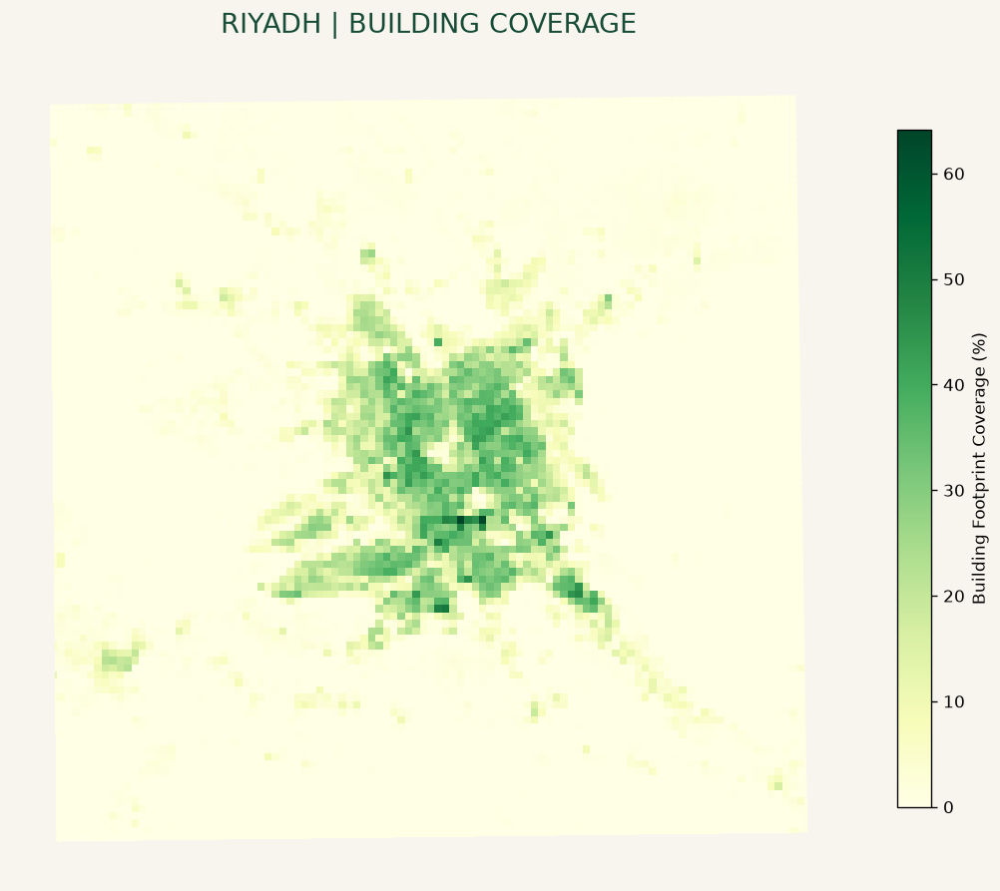

In [9]:

# ============================================================
# 08 | BUILDING FOOTPRINT COVERAGE ANALYSIS
# 1 km spatial grid | Original acquisition study extent
# ============================================================

import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import box

GRID_SIZE = 1000
TARGET_CRS = "EPSG:32638"

output_grid = data_dir / "riyadh_building_density_1km.gpkg"

# Original study extent, independent of the final atlas window
source_area = gpd.GeoDataFrame(
    geometry=[
        box(46.20, 24.25, 47.20, 25.15)
    ],
    crs="EPSG:4326"
)

source_metric = source_area.to_crs(TARGET_CRS)

# ------------------------------------------------------------
# 1 | LOAD EXISTING ANALYSIS
# ------------------------------------------------------------

if output_grid.exists():

    print("EXISTING DENSITY ANALYSIS FOUND")
    print("Loading saved results...")

    grid = gpd.read_file(
        output_grid,
        layer="building_density"
    )

# ------------------------------------------------------------
# 2 | CALCULATE ONLY IF RESULTS ARE MISSING
# ------------------------------------------------------------

else:

    print("Calculating building footprint coverage...")

    buildings_metric = buildings_polygon.to_crs(
        TARGET_CRS
    )

    xmin, ymin, xmax, ymax = source_metric.total_bounds

    x_coords = np.arange(xmin, xmax, GRID_SIZE)
    y_coords = np.arange(ymin, ymax, GRID_SIZE)

    grid_polygons = [
        box(x, y, x + GRID_SIZE, y + GRID_SIZE)
        for x in x_coords
        for y in y_coords
    ]

    grid = gpd.GeoDataFrame(
        {"grid_id": range(len(grid_polygons))},
        geometry=grid_polygons,
        crs=TARGET_CRS
    )

    grid = gpd.clip(
        grid,
        source_metric
    )

    grid["cell_area_m2"] = grid.geometry.area

    intersections = gpd.overlay(
        buildings_metric[["geometry"]],
        grid[["grid_id", "geometry"]],
        how="intersection",
        keep_geom_type=True
    )

    intersections["building_area_m2"] = (
        intersections.geometry.area
    )

    coverage = (
        intersections.groupby("grid_id")[
            "building_area_m2"
        ].sum()
    )

    grid["building_area_m2"] = (
        grid["grid_id"]
        .map(coverage)
        .fillna(0)
    )

    grid["coverage_pct"] = (
        grid["building_area_m2"]
        / grid["cell_area_m2"]
        * 100
    )

    grid.to_file(
        output_grid,
        layer="building_density",
        driver="GPKG"
    )

# ------------------------------------------------------------
# 3 | VALIDATE RESULTS
# ------------------------------------------------------------

required_columns = [
    "grid_id",
    "cell_area_m2",
    "building_area_m2",
    "coverage_pct"
]

missing_columns = [
    column
    for column in required_columns
    if column not in grid.columns
]

if missing_columns:
    raise ValueError(
        f"Missing density columns: {missing_columns}"
    )

print("\nRIYADH | BUILDING COVERAGE ANALYSIS")
print("=" * 50)

print("Grid cells:", f"{len(grid):,}")
print("Maximum coverage:", f"{grid['coverage_pct'].max():.2f}%")
print("Mean cell coverage:", f"{grid['coverage_pct'].mean():.2f}%")

weighted_coverage = (
    grid["building_area_m2"].sum()
    / grid["cell_area_m2"].sum()
    * 100
)

print("Area-weighted coverage:", f"{weighted_coverage:.2f}%")
print("CRS:", grid.crs)
print("Saved file:", output_grid)

# ------------------------------------------------------------
# 4 | COMPACT ANALYTICAL PREVIEW
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 9),
    dpi=120
)

fig.patch.set_facecolor("#F8F5EE")
ax.set_facecolor("#F8F5EE")

grid.plot(
    column="coverage_pct",
    ax=ax,
    cmap="YlGn",
    legend=True,
    linewidth=0,
    legend_kwds={
        "label": "Building Footprint Coverage (%)",
        "shrink": 0.65
    }
)

ax.set_title(
    "RIYADH | BUILDING COVERAGE",
    fontsize=16,
    color="#174D38",
    pad=15
)

ax.set_axis_off()
ax.set_aspect("equal")

plt.tight_layout()
plt.show()


In [16]:

import numpy as np
import pandas as pd

# ==================================================
# RIYADH | BUILDING DENSITY QUALITY ASSESSMENT
# ==================================================

print("RIYADH SPATIAL ATLAS | DATA QUALITY")
print("=" * 55)

# Basic grid statistics
print("Total grid cells:", f"{len(grid):,}")
print("Cells with buildings:", f"{(grid['coverage_pct'] > 0).sum():,}")
print("Cells without buildings:", f"{(grid['coverage_pct'] == 0).sum():,}")

print("\nBUILDING COVERAGE STATISTICS")
print("-" * 55)

print(
    grid["coverage_pct"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2).to_string()
)

# Detect unusual coverage values
over_100 = (grid["coverage_pct"] > 100).sum()
negative = (grid["coverage_pct"] < 0).sum()

print("\nQUALITY CHECKS")
print("-" * 55)
print("Cells exceeding 100% coverage:", over_100)
print("Cells with negative coverage:", negative)
print("Invalid grid geometries:", (~grid.is_valid).sum())

# Area-weighted overall building coverage
total_building_area = grid["building_area_m2"].sum()
total_grid_area = grid["cell_area_m2"].sum()

overall_coverage = (
    total_building_area / total_grid_area * 100
)

print("\nSTUDY AREA SUMMARY")
print("-" * 55)
print("Total study area (km²):", round(total_grid_area / 1e6, 2))
print("Summed building footprint area (km²):",
      round(total_building_area / 1e6, 2))
print("Overall building coverage (%):",
      round(overall_coverage, 2))

print("\nQuality assessment completed.")


RIYADH SPATIAL ATLAS | DATA QUALITY
Total grid cells: 10,273
Cells with buildings: 6,980
Cells without buildings: 3,293

BUILDING COVERAGE STATISTICS
-------------------------------------------------------
count    10273.00
mean         3.34
std          8.27
min          0.00
25%          0.00
50%          0.05
75%          0.98
90%         12.49
95%         25.62
99%         36.97
max         64.13

QUALITY CHECKS
-------------------------------------------------------
Cells exceeding 100% coverage: 0
Cells with negative coverage: 0
Invalid grid geometries: 0

STUDY AREA SUMMARY
-------------------------------------------------------
Total study area (km²): 10087.5
Summed building footprint area (km²): 342.4
Overall building coverage (%): 3.39

Quality assessment completed.


In [11]:

import geopandas as gpd
from pathlib import Path

# =====================================================
# RIYADH | URBAN CANDIDATE CLASSIFICATION
# Reuse saved building density results
# =====================================================

# Find project root
current = Path.cwd().resolve()

project_root = next(
    (
        p for p in [current, *current.parents]
        if (p / "data" / "day09_building_footprints").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Project data folder not found. Check Jupyter working directory."
    )

data_dir = project_root / "data" / "day09_building_footprints"

density_file = data_dir / "riyadh_building_density_1km.gpkg"
output_file = data_dir / "riyadh_urban_candidate_5pct.gpkg"

print("Project root:", project_root)
print("Density file exists:", density_file.exists())
print("Urban candidate file exists:", output_file.exists())

# Reuse saved output if available
if output_file.exists():
    urban_cells = gpd.read_file(
        output_file,
        layer="urban_candidate"
    )
    print("\nExisting urban candidate data loaded.")

elif density_file.exists():
    density = gpd.read_file(
        density_file,
        layer="building_density"
    )

    THRESHOLD = 5.0

    urban_cells = density.loc[
        density["coverage_pct"] >= THRESHOLD
    ].copy()

    urban_cells["urban_candidate"] = True

    urban_cells.to_file(
        output_file,
        layer="urban_candidate",
        driver="GPKG"
    )

    print("\nUrban candidate classification saved.")

else:
    raise FileNotFoundError(
        f"Neither saved dataset was found in: {data_dir}"
    )

print("\nRIYADH | URBAN CANDIDATE DATA READY")
print("=" * 45)
print(f"Candidate cells: {len(urban_cells):,}")
print("CRS:", urban_cells.crs)
print("File:", output_file)


Project root: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026
Density file exists: True
Urban candidate file exists: True

Existing urban candidate data loaded.

RIYADH | URBAN CANDIDATE DATA READY
Candidate cells: 1,527
CRS: EPSG:32638
File: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\data\day09_building_footprints\riyadh_urban_candidate_5pct.gpkg


In [12]:

import geopandas as gpd

# =====================================================
# RIYADH | URBAN CLUSTER DATA
# Reuse previously calculated spatial clusters
# =====================================================

cluster_file = data_dir / "riyadh_urban_clusters.gpkg"
main_file = data_dir / "riyadh_main_urban_cluster.gpkg"

print("Cluster file exists:", cluster_file.exists())
print("Main cluster file exists:", main_file.exists())

if not cluster_file.exists() or not main_file.exists():
    raise FileNotFoundError(
        "Saved urban cluster data missing. "
        "Do not delete earlier processing cells yet."
    )

clusters = gpd.read_file(cluster_file).to_crs("EPSG:32638")

main_cluster = gpd.read_file(
    main_file,
    layer="main_cluster"
).to_crs("EPSG:32638")

print("\nRIYADH | URBAN CLUSTERS READY")
print("=" * 45)
print("Cluster records:", f"{len(clusters):,}")
print("Main cluster records:", f"{len(main_cluster):,}")
print("Cluster columns:", clusters.columns.tolist())
print("Main cluster area:", f"{main_cluster.geometry.area.sum()/1e6:,.2f} km²")
print("CRS:", main_cluster.crs)


Cluster file exists: True
Main cluster file exists: True

RIYADH | URBAN CLUSTERS READY
Cluster records: 84
Main cluster records: 1
Cluster columns: ['area_km2', 'cluster_id', 'geometry']
Main cluster area: 1,219.00 km²
CRS: EPSG:32638


In [12]:

from pathlib import Path
import geopandas as gpd
import pandas as pd

# RIYADH ATLAS | ROAD DOWNLOAD STATUS
project_root = Path.cwd().resolve().parents[1]
road_dir = project_root / "data" / "day09_building_footprints" / "roads_extended"

records = []

for row in range(1, 4):
    for col in range(1, 4):
        tile_id = f"r{row}_c{col}"
        path = road_dir / f"roads_{tile_id}.gpkg"

        if path.exists():
            try:
                roads_tile = gpd.read_file(path, layer="roads")
                records.append({
                    "Tile": tile_id,
                    "Status": "COMPLETE",
                    "Segments": len(roads_tile)
                })
            except Exception as error:
                records.append({
                    "Tile": tile_id,
                    "Status": f"ERROR: {error}",
                    "Segments": 0
                })
        else:
            records.append({
                "Tile": tile_id,
                "Status": "MISSING",
                "Segments": 0
            })

status = pd.DataFrame(records)

print(status.to_string(index=False))
print()
print("Completed:", (status["Status"] == "COMPLETE").sum(), "/ 9")
print("Missing:", (status["Status"] == "MISSING").sum())
print("Saved segments:", f"{status['Segments'].sum():,}")


 Tile   Status  Segments
r1_c1 COMPLETE     22477
r1_c2  MISSING         0
r1_c3 COMPLETE     22209
r2_c1 COMPLETE     17489
r2_c2 COMPLETE    121162
r2_c3  MISSING         0
r3_c1  MISSING         0
r3_c2  MISSING         0
r3_c3  MISSING         0

Completed: 4 / 9
Missing: 5
Saved segments: 183,337


Total road features: 111,685
CRS: EPSG:32638

Top road types:
highway
residential       61761
service           20951
tertiary           5946
living_street      5371
footway            3418
unclassified       2697
secondary          2318
primary            1596
tertiary_link      1503
construction        893
primary_link        886
secondary_link      851
motorway_link       844
motorway            622
track               370
Name: count, dtype: int64


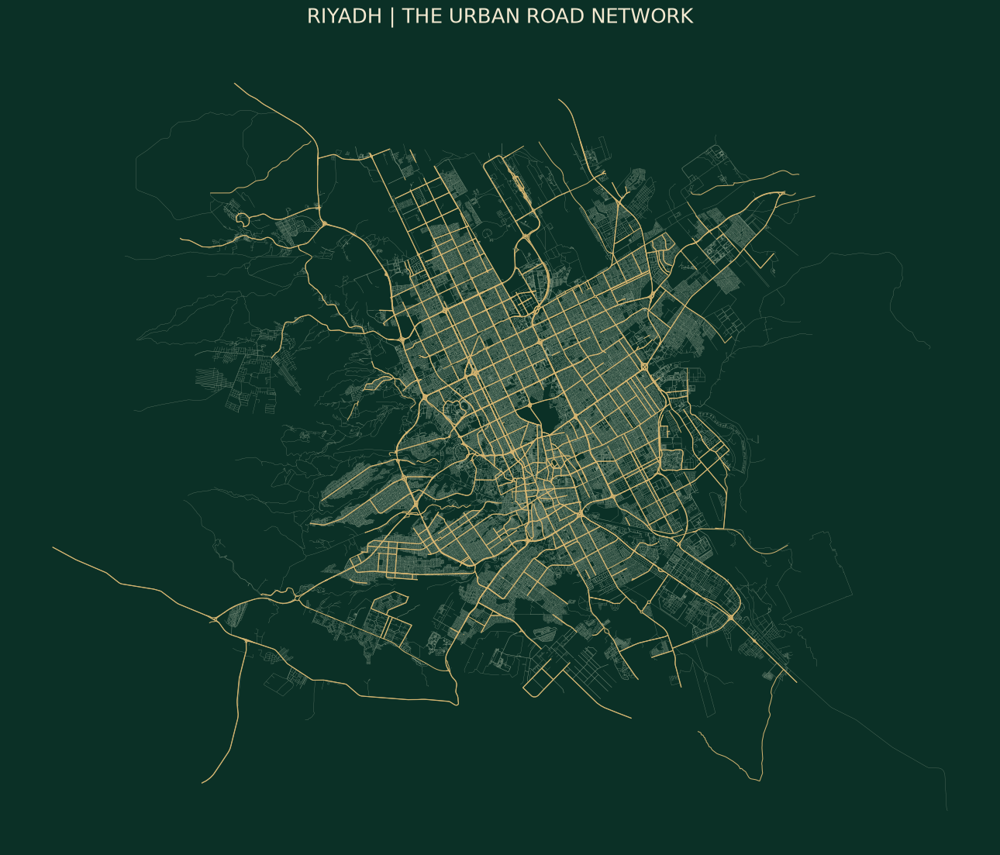


Road features used: 106,216


In [14]:

import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
project_root = Path.cwd().resolve().parents[1]
data_dir = project_root / "data" / "day09_building_footprints"

roads_path = data_dir / "riyadh_roads_local.gpkg"

# Load roads
roads = gpd.read_file(roads_path, layer="roads")

print("Total road features:", f"{len(roads):,}")
print("CRS:", roads.crs)
print("\nTop road types:")
print(roads["highway"].value_counts().head(15))

# Exclude non-road features
excluded = [
    "footway", "path", "steps", "cycleway",
    "pedestrian", "bridleway", "construction",
    "proposed", "platform"
]

roads = roads[
    roads["highway"].notna()
    & ~roads["highway"].isin(excluded)
].copy()

# Separate major and local roads
major_types = [
    "motorway", "motorway_link",
    "trunk", "trunk_link",
    "primary", "primary_link",
    "secondary", "secondary_link"
]

major = roads[roads["highway"].isin(major_types)]
local = roads[~roads["highway"].isin(major_types)]

# Map
fig, ax = plt.subplots(
    figsize=(13, 13),
    facecolor="#0B3026"
)

ax.set_facecolor("#0B3026")

local.plot(
    ax=ax,
    color="#A7B7A0",
    linewidth=0.22,
    alpha=0.65,
    rasterized=True
)

major.plot(
    ax=ax,
    color="#D7B773",
    linewidth=0.75,
    alpha=0.95,
    rasterized=True
)

ax.set_title(
    "RIYADH | THE URBAN ROAD NETWORK",
    fontsize=19,
    color="#F3E9D1",
    pad=22
)

ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

print("\nRoad features used:", f"{len(roads):,}")


Buildings: 760,852
Roads: 104,974


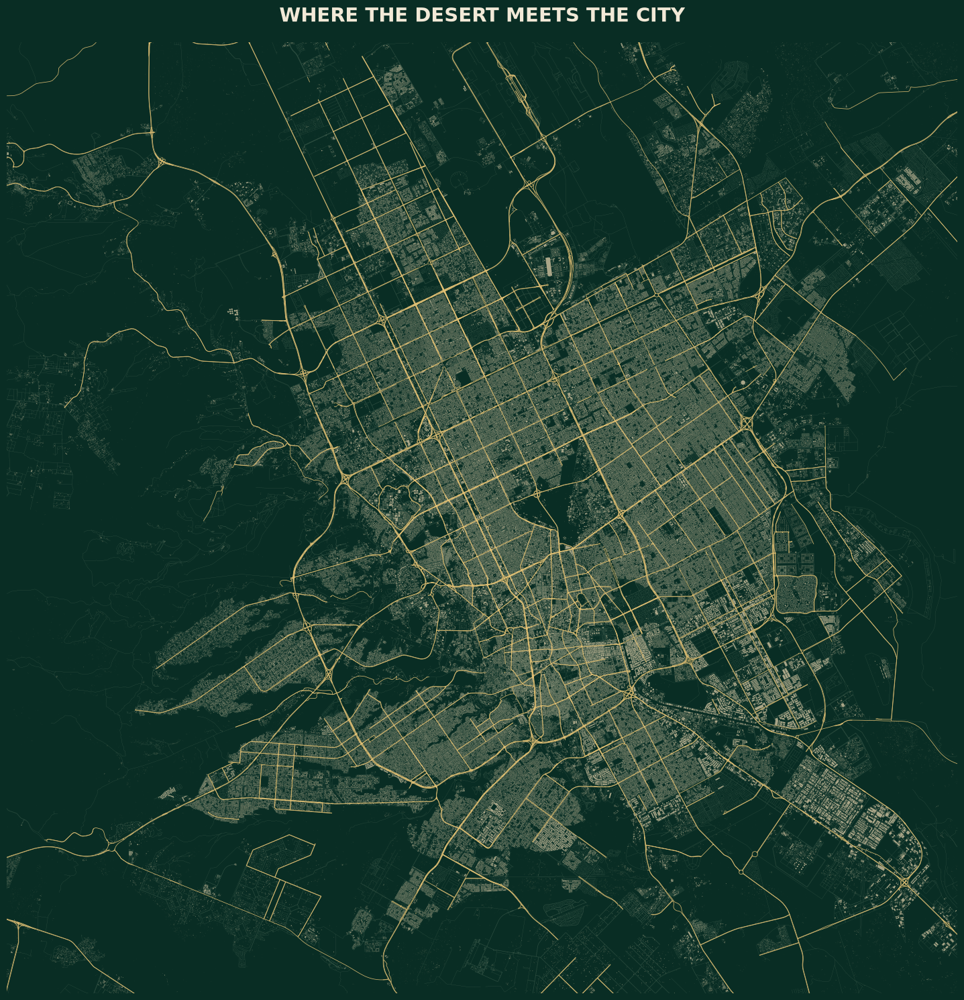

In [15]:

import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import box

# ==================================================
# RIYADH | BUILDINGS + ROADS
# CARTOGRAPHIC COMPOSITION TEST
# ==================================================

root = Path.cwd().resolve().parents[1]
data = root / "data" / "day09_building_footprints"

CRS = "EPSG:32638"

buildings = gpd.read_file(
    data / "riyadh_buildings.gpkg",
    layer="building_footprints"
).to_crs(CRS)

roads = gpd.read_file(
    data / "riyadh_roads_local.gpkg",
    layer="roads"
).to_crs(CRS)

# Use the exact original 60 km study square
center = gpd.GeoSeries(
    gpd.points_from_xy([46.6753], [24.7136]),
    crs="EPSG:4326"
).to_crs(CRS).iloc[0]

cx, cy = center.x, center.y

extent = box(
    cx - 30000, cy - 30000,
    cx + 30000, cy + 30000
)

# Spatially filter data
buildings = buildings[
    buildings.intersects(extent)
].copy()

roads = roads[
    roads.intersects(extent)
    & roads["highway"].notna()
].copy()

# Polygon geometries only
buildings = buildings[
    buildings.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
]

major_types = [
    "motorway", "motorway_link",
    "trunk", "trunk_link",
    "primary", "primary_link",
    "secondary", "secondary_link"
]

excluded = [
    "footway", "path", "steps",
    "cycleway", "pedestrian",
    "bridleway", "construction",
    "proposed", "platform"
]

roads = roads[~roads["highway"].isin(excluded)]

major = roads[roads["highway"].isin(major_types)]
minor = roads[~roads["highway"].isin(major_types)]

print("Buildings:", f"{len(buildings):,}")
print("Roads:", f"{len(roads):,}")

# ==================================================
# MAP
# ==================================================

fig, ax = plt.subplots(
    figsize=(15, 15),
    facecolor="#092D24"
)
ax.set_facecolor("#092D24")

# Urban fabric
buildings.plot(
    ax=ax,
    color="#D8C9A5",
    edgecolor="none",
    linewidth=0,
    alpha=0.78,
    rasterized=True,
    zorder=2
)

# Local roads
minor.plot(
    ax=ax,
    color="#748F79",
    linewidth=0.16,
    alpha=0.55,
    rasterized=True,
    zorder=3
)

# Major roads
major.plot(
    ax=ax,
    color="#E6C477",
    linewidth=0.55,
    alpha=0.92,
    rasterized=True,
    zorder=4
)

ax.set_xlim(cx - 30000, cx + 30000)
ax.set_ylim(cy - 30000, cy + 30000)
ax.set_aspect("equal")

ax.axis("off")

ax.set_title(
    "WHERE THE DESERT MEETS THE CITY",
    color="#F2E9D7",
    fontsize=21,
    fontweight="bold",
    pad=22
)

plt.tight_layout()
plt.show()


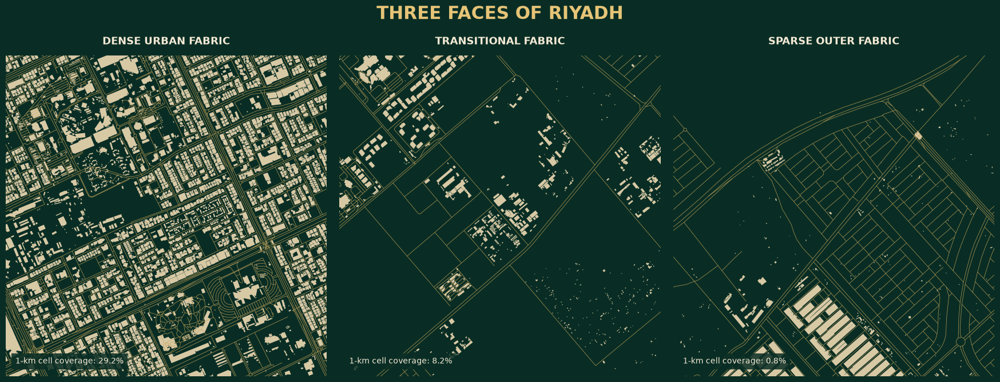


SELECTED LOCATIONS
DENSE URBAN FABRIC: 29.19% coverage
TRANSITIONAL FABRIC: 8.18% coverage
SPARSE OUTER FABRIC: 0.81% coverage

Saved: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day09_urban_rural\riyadh_morphology_comparison.png


In [17]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import box

# ============================================================
# DAY 09 | URBAN MORPHOLOGY
# Three comparable views of Riyadh's built fabric
# ============================================================

root = Path.cwd().resolve().parents[1]
data_dir = root / "data" / "day09_building_footprints"
out_dir = root / "maps" / "day09_urban_rural"
out_dir.mkdir(parents=True, exist_ok=True)

CRS = "EPSG:32638"
VIEW_SIZE = 2500  # metres: same extent for all panels

density = gpd.read_file(
    data_dir / "riyadh_building_density_1km.gpkg",
    layer="building_density"
).to_crs(CRS)

buildings_path = data_dir / "riyadh_buildings.gpkg"
roads_path = data_dir / "riyadh_roads_local.gpkg"

# Limit selection to the central 60 km square
center = gpd.GeoSeries(
    gpd.points_from_xy([46.6753], [24.7136]),
    crs="EPSG:4326"
).to_crs(CRS).iloc[0]

cx, cy = center.x, center.y
study_area = box(cx-30000, cy-30000, cx+30000, cy+30000)

density = density[
    density.geometry.centroid.within(study_area)
].copy()

# Select examples from different coverage ranges.
# These are illustrative samples, not official land-use classes.
ranges = [
    ("DENSE URBAN FABRIC", 20, 60),
    ("TRANSITIONAL FABRIC", 5, 12),
    ("SPARSE OUTER FABRIC", 0.3, 2)
]

selected = []

for label, low, high in ranges:
    candidates = density[
        density["coverage_pct"].between(low, high)
    ].copy()

    if candidates.empty:
        raise ValueError(
            f"No grid cells found for {label}"
        )

    # Choose a representative cell near the median coverage
    median_value = candidates["coverage_pct"].median()

    candidates["difference"] = (
        candidates["coverage_pct"] - median_value
    ).abs()

    chosen = candidates.sort_values(
        "difference"
    ).iloc[0]

    selected.append({
        "label": label,
        "coverage": chosen["coverage_pct"],
        "center": chosen.geometry.centroid
    })

# Load vector data once
buildings = gpd.read_file(
    buildings_path,
    layer="building_footprints"
).to_crs(CRS)

roads = gpd.read_file(
    roads_path,
    layer="roads"
).to_crs(CRS)

buildings = buildings[
    buildings.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

# ============================================================
# THREE-PANEL COMPARISON
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7),
    facecolor="#092D24"
)

for ax, item in zip(axes, selected):
    p = item["center"]
    half = VIEW_SIZE / 2

    bounds = box(
        p.x-half, p.y-half,
        p.x+half, p.y+half
    )

    local_buildings = buildings[
        buildings.intersects(bounds)
    ]

    local_roads = roads[
        roads.intersects(bounds)
    ]

    ax.set_facecolor("#092D24")

    if not local_buildings.empty:
        local_buildings.plot(
            ax=ax,
            color="#D8C9A5",
            edgecolor="none",
            linewidth=0,
            rasterized=True,
            zorder=2
        )

    if not local_roads.empty:
        local_roads.plot(
            ax=ax,
            color="#C5A45A",
            linewidth=0.55,
            alpha=0.85,
            rasterized=True,
            zorder=3
        )

    ax.set_xlim(p.x-half, p.x+half)
    ax.set_ylim(p.y-half, p.y+half)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.set_title(
        item["label"],
        color="#F4EAD6",
        fontsize=13,
        fontweight="bold",
        pad=14
    )

    ax.text(
        0.03, 0.04,
        f"1-km cell coverage: {item['coverage']:.1f}%",
        transform=ax.transAxes,
        color="#F4EAD6",
        fontsize=10,
        bbox=dict(
            facecolor="#092D24",
            edgecolor="none",
            alpha=0.85,
            pad=5
        )
    )

fig.suptitle(
    "THREE FACES OF RIYADH",
    color="#E6C477",
    fontsize=22,
    fontweight="bold",
    y=0.99
)

plt.subplots_adjust(
    left=0.02, right=0.98,
    bottom=0.05, top=0.88,
    wspace=0.04
)

output = out_dir / "riyadh_morphology_comparison.png"

fig.savefig(
    output,
    dpi=220,
    facecolor=fig.get_facecolor(),
    bbox_inches="tight"
)

plt.show()

print("\nSELECTED LOCATIONS")
for item in selected:
    print(
        f"{item['label']}: "
        f"{item['coverage']:.2f}% coverage"
    )

print("\nSaved:", output)


Project root: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026
Data folder: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\data\day09_building_footprints
Output folder: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day09_urban_rural

01 / Loading datasets...
Buildings: 760,852
Road features: 104,974

02 / Evaluating candidate windows...

Selected windows:
COMPACT 25.06% 2,374 features
INTERMEDIATE 8.44% 1,553 features
SPARSE 0.96% 666 features

03 / Rendering poster...

04 / Exporting final poster...


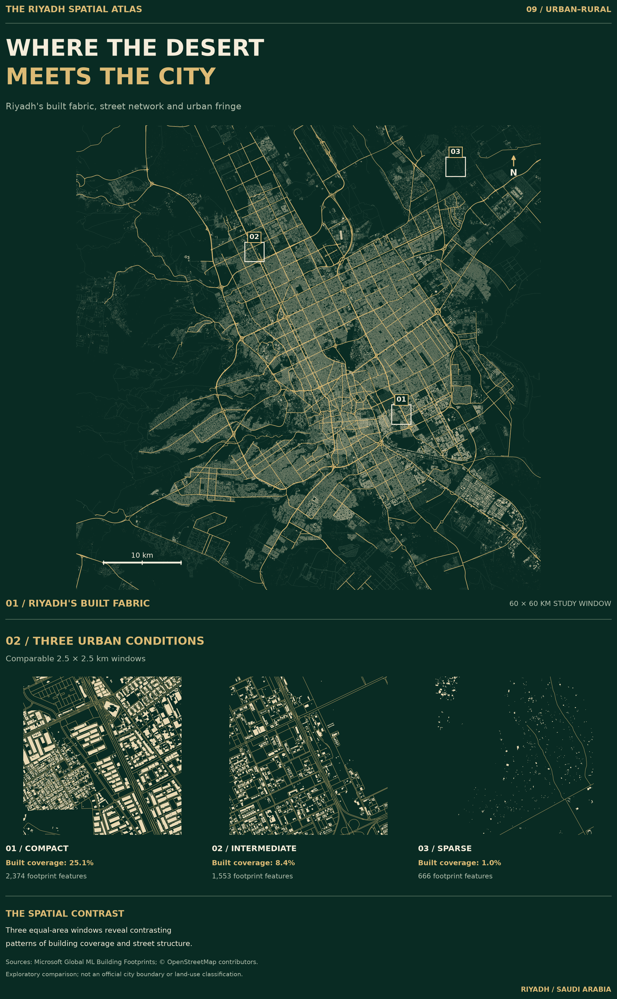


FINAL ATLAS EXPORTED
PNG: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day09_urban_rural\WHERE_THE_DESERT_MEETS_THE_CITY_FINAL.png
PDF: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day09_urban_rural\WHERE_THE_DESERT_MEETS_THE_CITY_FINAL.pdf
Resolution: 2400 x 3600 pixels
01 COMPACT: 25.06% built coverage
02 INTERMEDIATE: 8.44% built coverage
03 SPARSE: 0.96% built coverage


In [16]:

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from shapely.geometry import box
from shapely.ops import unary_union
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

# ============================================================
# WHERE THE DESERT MEETS THE CITY
# RIYADH SPATIAL ATLAS | DAY 09
# FINAL DIGITAL EDITION
# ============================================================

# 01 | PROJECT CONFIGURATION

PROJECT_NAME = "Riyadh-30DayMapChallenge-2026"
DATA_SUBDIR = Path("data") / "day09_building_footprints"
REQUIRED_FILE = "riyadh_buildings.gpkg"

cwd = Path.cwd().resolve()

# Search the current folder, its parents, and likely
# project subfolders. Notebook filename does not matter.
candidates = []

for parent in (cwd, *cwd.parents):
    candidates.append(parent)
    candidates.append(parent / PROJECT_NAME)
    candidates.append(parent / PROJECT_NAME / PROJECT_NAME)

# Remove duplicates while preserving order
candidates = list(dict.fromkeys(candidates))

ROOT = next(
    (
        folder for folder in candidates
        if (folder / DATA_SUBDIR / REQUIRED_FILE).is_file()
    ),
    None
)

if ROOT is None:
    print("Current working directory:", cwd)
    print("\nSearched project locations:")
    for folder in candidates:
        print(" -", folder / DATA_SUBDIR / REQUIRED_FILE)

    raise FileNotFoundError(
        "Could not locate riyadh_buildings.gpkg. "
        "Check that the project's data folder still exists."
    )

DATA = ROOT / DATA_SUBDIR
OUT = ROOT / "maps" / "day09_urban_rural"
OUT.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Data folder:", DATA)
print("Output folder:", OUT)

CRS = "EPSG:32638"
DPI = 200

BG = "#092B23"
GOLD = "#DDBB75"
SAND = "#E9D9B4"
CREAM = "#F5EDDB"
MUTED = "#B3C0AE"
ROAD = "#829B83"
LINE = "#52705D"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.facecolor": BG,
    "savefig.facecolor": BG
})

# ------------------------------------------------------------
# 02 | STUDY AREA
# ------------------------------------------------------------

center = gpd.GeoSeries(
    gpd.points_from_xy([46.6753], [24.7136]),
    crs="EPSG:4326"
).to_crs(CRS).iloc[0]

cx, cy = center.x, center.y

HALF = 30000
VIEW = 2500
H = VIEW / 2

study = box(
    cx-HALF, cy-HALF,
    cx+HALF, cy+HALF
)

print("\n01 / Loading datasets...", flush=True)

def load_spatial(filename, layer):
    path = DATA / filename

    if not path.exists():
        raise FileNotFoundError(path)

    import pyogrio

    info = pyogrio.read_info(path, layer=layer)
    source_crs = info["crs"]

    bbox_source = gpd.GeoSeries(
        [study], crs=CRS
    ).to_crs(source_crs).total_bounds

    result = gpd.read_file(
        path,
        layer=layer,
        bbox=tuple(bbox_source)
    )

    return result.to_crs(CRS)


buildings = load_spatial(
    "riyadh_buildings.gpkg",
    "building_footprints"
)

roads = load_spatial(
    "riyadh_roads_local.gpkg",
    "roads"
)

density = load_spatial(
    "riyadh_building_density_1km.gpkg",
    "building_density"
)

buildings = buildings[
    buildings.geometry.notna()
    & buildings.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

buildings = buildings[
    buildings.intersects(study)
].copy()

roads = roads[
    roads.geometry.notna()
    & roads["highway"].notna()
    & roads.intersects(study)
].copy()

excluded = {
    "footway", "path", "steps",
    "cycleway", "pedestrian",
    "bridleway", "platform",
    "construction", "proposed"
}

roads = roads[
    ~roads["highway"].isin(excluded)
].copy()

major_types = {
    "motorway", "motorway_link",
    "trunk", "trunk_link",
    "primary", "primary_link",
    "secondary", "secondary_link"
}

major = roads[
    roads["highway"].isin(major_types)
].copy()

minor = roads[
    ~roads["highway"].isin(major_types)
].copy()

print("Buildings:", f"{len(buildings):,}")
print("Road features:", f"{len(roads):,}")

# ------------------------------------------------------------
# 03 | SELECT WINDOWS USING ACTUAL WINDOW COVERAGE
# ------------------------------------------------------------

print("\n02 / Evaluating candidate windows...", flush=True)

density["coverage_pct"] = pd.to_numeric(
    density["coverage_pct"],
    errors="coerce"
)

density = density.dropna(subset=["coverage_pct"])

density["candidate_point"] = density.geometry.centroid

safe_area = study.buffer(-H-100)

density = density[
    density["candidate_point"].within(safe_area)
].copy()

classes = [
    ("COMPACT", 20, 60),
    ("INTERMEDIATE", 5, 12),
    ("SPARSE", 0.3, 2)
]


def evaluate_window(point):
    window = box(
        point.x-H, point.y-H,
        point.x+H, point.y+H
    )

    b = buildings[
        buildings.intersects(window)
    ].copy()

    r = roads[
        roads.intersects(window)
    ].copy()

    if b.empty:
        return {
            "window": window,
            "buildings": b,
            "roads": r,
            "coverage": 0.0,
            "count": 0
        }

    clipped = b.geometry.intersection(window)

    clipped = clipped[
        ~clipped.is_empty
    ]

    clipped = clipped.apply(
        lambda geom: geom
        if geom.is_valid
        else geom.buffer(0)
    )

    merged = unary_union(clipped.tolist())

    coverage = (
        merged.area / window.area * 100
        if not merged.is_empty
        else 0.0
    )

    return {
        "window": window,
        "buildings": b,
        "roads": r,
        "coverage": coverage,
        "count": len(b)
    }


samples = []
targets = [25.0, 8.0, 1.0]

for (name, low, high), target in zip(classes, targets):

    candidates = density[
        density["coverage_pct"].between(low, high)
    ].copy()

    if candidates.empty:
        raise RuntimeError(
            f"No candidates for {name}"
        )

    candidates["rank"] = (
        candidates["coverage_pct"] - target
    ).abs()

    candidates = candidates.sort_values("rank")

    evaluated = []

    for _, row in candidates.head(25).iterrows():

        p = row["candidate_point"]

        if any(
            p.distance(s["point"]) < 6000
            for s in samples
        ):
            continue

        result = evaluate_window(p)

        evaluated.append({
            "point": p,
            **result
        })

    if not evaluated:
        raise RuntimeError(
            f"No separated candidates for {name}"
        )

    best = min(
        evaluated,
        key=lambda x: abs(
            x["coverage"] - target
        )
    )

    best["name"] = name
    samples.append(best)

print("\nSelected windows:")

for sample in samples:
    print(
        sample["name"],
        f"{sample['coverage']:.2f}%",
        f"{sample['count']:,} features"
    )

# ------------------------------------------------------------
# 04 | CARTOGRAPHIC FUNCTIONS
# ------------------------------------------------------------

print("\n03 / Rendering poster...", flush=True)

fig = plt.figure(
    figsize=(12, 18),
    dpi=DPI,
    facecolor=BG
)


def text(x, y, content, size=10,
         color=CREAM, weight="normal",
         align="left"):

    fig.text(
        x, y, content,
        fontsize=size,
        color=color,
        weight=weight,
        ha=align,
        va="center"
    )


def rule(y):
    fig.add_artist(Line2D(
        [0.055, 0.945],
        [y, y],
        transform=fig.transFigure,
        color=LINE,
        linewidth=0.8
    ))


def setup_map(ax, x, y, half):
    ax.set_xlim(x-half, x+half)
    ax.set_ylim(y-half, y+half)
    ax.set_aspect("equal")
    ax.set_facecolor(BG)
    ax.axis("off")


# ------------------------------------------------------------
# 05 | HEADER
# ------------------------------------------------------------

text(
    0.055, 0.973,
    "THE RIYADH SPATIAL ATLAS",
    11, GOLD, "bold"
)

text(
    0.945, 0.973,
    "09 / URBAN–RURAL",
    10, GOLD, "bold", "right"
)

rule(0.960)

text(
    0.055, 0.934,
    "WHERE THE DESERT",
    29, CREAM, "bold"
)

text(
    0.055, 0.906,
    "MEETS THE CITY",
    29, GOLD, "bold"
)

text(
    0.055, 0.878,
    "Riyadh's built fabric, street network and urban fringe",
    11, MUTED
)

# ------------------------------------------------------------
# 06 | MAIN MAP
# ------------------------------------------------------------

ax = fig.add_axes(
    [0.055, 0.405, 0.89, 0.455]
)

ax.set_facecolor(BG)

buildings.plot(
    ax=ax,
    color=SAND,
    edgecolor="none",
    linewidth=0,
    alpha=0.86,
    rasterized=True,
    zorder=2
)

minor.plot(
    ax=ax,
    color=ROAD,
    linewidth=0.14,
    alpha=0.48,
    rasterized=True,
    zorder=3
)

major.plot(
    ax=ax,
    color=GOLD,
    linewidth=0.46,
    alpha=0.95,
    rasterized=True,
    zorder=4
)

for i, sample in enumerate(samples, 1):

    p = sample["point"]

    ax.add_patch(Rectangle(
        (p.x-H, p.y-H),
        VIEW, VIEW,
        fill=False,
        edgecolor=CREAM,
        linewidth=1.2,
        zorder=8
    ))

    ax.text(
        p.x, p.y+H+400,
        f"{i:02d}",
        ha="center",
        color=CREAM,
        fontsize=9,
        weight="bold",
        bbox=dict(
            facecolor=BG,
            edgecolor=GOLD,
            boxstyle="square,pad=0.25"
        ),
        zorder=9
    )

setup_map(ax, cx, cy, HALF)

ax.annotate(
    "N",
    xy=(cx+26500, cy+26400),
    xytext=(cx+26500, cy+23500),
    ha="center",
    color=CREAM,
    fontsize=11,
    weight="bold",
    arrowprops=dict(
        arrowstyle="-|>",
        color=GOLD,
        lw=1.4
    )
)

bx = cx - 26500
by = cy - 26500

ax.plot(
    [bx, bx+10000],
    [by, by],
    color=CREAM,
    lw=2.3,
    zorder=10
)

for offset in [0, 5000, 10000]:
    ax.plot(
        [bx+offset, bx+offset],
        [by-220, by+220],
        color=CREAM,
        lw=1.2,
        zorder=10
    )

ax.text(
    bx+5000, by+650,
    "10 km",
    color=CREAM,
    fontsize=9,
    ha="center"
)

text(
    0.055, 0.391,
    "01 / RIYADH'S BUILT FABRIC",
    12, GOLD, "bold"
)

text(
    0.945, 0.391,
    "60 × 60 KM STUDY WINDOW",
    9, MUTED, align="right"
)

rule(0.376)

# ------------------------------------------------------------
# 07 | THREE MORPHOLOGY WINDOWS
# ------------------------------------------------------------

text(
    0.055, 0.354,
    "02 / THREE URBAN CONDITIONS",
    14, GOLD, "bold"
)

text(
    0.055, 0.337,
    "Comparable 2.5 × 2.5 km windows",
    10, MUTED
)

panel_x = [0.055, 0.358, 0.661]
panel_y = 0.165
panel_w = 0.284
panel_h = 0.155

for i, (sample, px) in enumerate(
    zip(samples, panel_x), 1
):

    p = sample["point"]

    a = fig.add_axes([
        px, panel_y, panel_w, panel_h
    ])

    b = sample["buildings"]
    r = sample["roads"]

    if not b.empty:
        b.plot(
            ax=a,
            color=SAND,
            edgecolor="none",
            linewidth=0,
            rasterized=True,
            zorder=2
        )

    if not r.empty:
        r.plot(
            ax=a,
            color=GOLD,
            linewidth=0.40,
            alpha=0.85,
            rasterized=True,
            zorder=3
        )

    setup_map(a, p.x, p.y, H)

    text(
        px, 0.151,
        f"{i:02d} / {sample['name']}",
        10, CREAM, "bold"
    )

    text(
        px, 0.137,
        f"Built coverage: "
        f"{sample['coverage']:.1f}%",
        9, GOLD, "bold"
    )

    text(
        px, 0.124,
        f"{sample['count']:,} footprint features",
        8.5, MUTED
    )

# ------------------------------------------------------------
# 08 | INTERPRETATION AND SOURCES
# ------------------------------------------------------------

rule(0.105)

text(
    0.055, 0.087,
    "THE SPATIAL CONTRAST",
    11, GOLD, "bold"
)

text(
    0.055, 0.071,
    "Three equal-area windows reveal contrasting",
    9.5, CREAM
)

text(
    0.055, 0.058,
    "patterns of building coverage and street structure.",
    9.5, CREAM
)

text(
    0.055, 0.040,
    "Sources: Microsoft Global ML Building Footprints; © OpenStreetMap contributors.",
    8, MUTED
)

text(
    0.055, 0.028,
    "Exploratory comparison; not an official city boundary or land-use classification.",
    7.5, MUTED
)

text(
    0.945, 0.013,
    "RIYADH / SAUDI ARABIA",
    8.5, GOLD, "bold", "right"
)

# ------------------------------------------------------------
# 09 | FINAL EXPORT — PNG + PDF
# ------------------------------------------------------------

print("\n04 / Exporting final poster...", flush=True)

png_output = OUT / "WHERE_THE_DESERT_MEETS_THE_CITY_FINAL.png"
pdf_output = OUT / "WHERE_THE_DESERT_MEETS_THE_CITY_FINAL.pdf"

fig.savefig(
    png_output,
    dpi=DPI,
    facecolor=BG,
    bbox_inches=None,
    pad_inches=0
)

fig.savefig(
    pdf_output,
    dpi=DPI,
    facecolor=BG,
    bbox_inches=None,
    pad_inches=0
)

plt.show()
plt.close(fig)

print("\n" + "="*60)
print("FINAL ATLAS EXPORTED")
print("="*60)
print("PNG:", png_output)
print("PDF:", pdf_output)
print("Resolution: 2400 x 3600 pixels")

for i, s in enumerate(samples, 1):
    print(
        f"{i:02d} {s['name']}: "
        f"{s['coverage']:.2f}% built coverage"
    )



<div style="
    background:#FAF8F3;
    padding:38px 42px;
    font-family:Georgia,serif;
    border-top:2px solid #B39256;
    border-bottom:2px solid #B39256;
">

  <div style="
      color:#B39256;
      font-size:11px;
      letter-spacing:3px;
      font-weight:bold;
      margin-bottom:22px;
  ">
    RIYADH SPATIAL ATLAS / 2026
  </div>

  <h2 style="
      color:#174D38;
      font-size:32px;
      font-weight:normal;
      margin:0 0 12px 0;
  ">
    The Urban–Rural Transition
  </h2>

  <div style="
      width:65px;
      height:2px;
      background:#B39256;
      margin:18px 0 26px 0;
  "></div>

  <p style="
      color:#174D38;
      font-size:16px;
      line-height:1.9;
      max-width:760px;
      margin:0 0 18px 0;
  ">
    Riyadh's built environment reveals a clear contrast
    between compact urban districts, intermediate
    development patterns, and sparsely built outer areas.
  </p>

  <p style="
      color:#174D38;
      font-size:16px;
      line-height:1.9;
      max-width:760px;
      margin:0 0 18px 0;
  ">
    Differences in building footprint coverage illustrate
    how the city's physical fabric changes across space.
    Together, these patterns provide an exploratory
    perspective on Riyadh's urban form and its transition
    toward the surrounding desert.
  </p>

  <div style="
      border-top:1px solid #D8C8A8;
      margin-top:28px;
      padding-top:15px;
      color:#65766D;
      font-size:11px;
      letter-spacing:1px;
  ">
    DAY 09 — URBAN–RURAL
    &nbsp; | &nbsp;
    WHERE THE DESERT MEETS THE CITY
  </div>

</div>


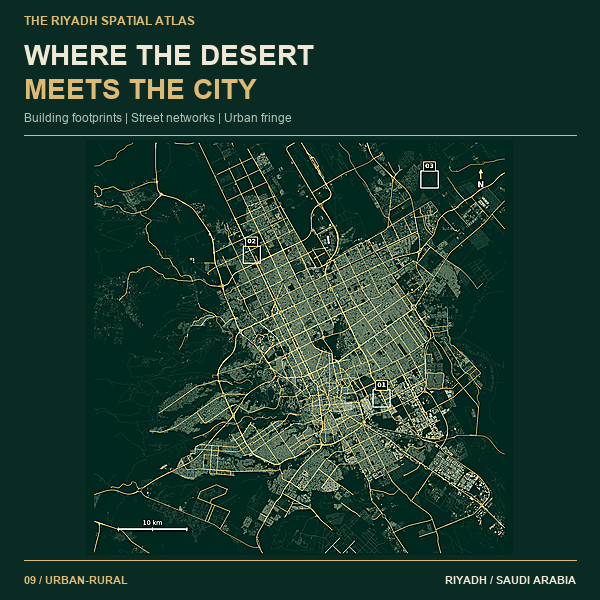

RIYADH SPATIAL ATLAS — DAY 09
Thumbnail: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day09_urban_rural\09-alhaylam-alajmi.png
Resolution: (600, 600)
File size: 358.9 KB
Status: Enhanced thumbnail exported


In [4]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont, ImageEnhance, ImageFilter
from IPython.display import display

# ============================================================
# RIYADH SPATIAL ATLAS | DAY 09
# ENHANCED MUSA GALLERY THUMBNAIL — 600 × 600
# ============================================================

# 1. Locate original poster
cwd = Path.cwd().resolve()

search_paths = [cwd, *cwd.parents]
search_paths += [
    p / "Riyadh-30DayMapChallenge-2026"
    for p in search_paths
]

ROOT = next(
    (
        p for p in search_paths
        if (
            p / "maps" / "day09_urban_rural" /
            "WHERE_THE_DESERT_MEETS_THE_CITY_FINAL.png"
        ).exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError("Original Riyadh poster not found.")

MAP_DIR = ROOT / "maps" / "day09_urban_rural"
SOURCE = MAP_DIR / "WHERE_THE_DESERT_MEETS_THE_CITY_FINAL.png"
OUTPUT = MAP_DIR / "09-alhaylam-alajmi.png"

poster = Image.open(SOURCE).convert("RGB")
W, H = poster.size

# 2. Design settings
SIZE = 600

BG = "#092B23"
GOLD = "#DDBB75"
IVORY = "#F0E7D4"
MUTED = "#B3C3B7"

thumb = Image.new("RGB", (SIZE, SIZE), BG)
draw = ImageDraw.Draw(thumb)

# 3. Fonts
font_dir = Path("C:/Windows/Fonts")

def get_font(name, size):
    path = font_dir / name
    if path.exists():
        return ImageFont.truetype(str(path), size)
    return ImageFont.load_default()

font_small = get_font("arialbd.ttf", 12)
font_title = get_font("arialbd.ttf", 28)
font_subtitle = get_font("arial.ttf", 12)
font_footer = get_font("arialbd.ttf", 11)

# 4. Compact header
draw.text(
    (24, 14),
    "THE RIYADH SPATIAL ATLAS",
    font=font_small,
    fill=GOLD
)

draw.text(
    (24, 39),
    "WHERE THE DESERT",
    font=font_title,
    fill=IVORY
)

draw.text(
    (24, 73),
    "MEETS THE CITY",
    font=font_title,
    fill=GOLD
)

draw.text(
    (24, 111),
    "Building footprints | Street networks | Urban fringe",
    font=font_subtitle,
    fill=MUTED
)

draw.line(
    (24, 135, 576, 135),
    fill=GOLD,
    width=1
)

# 5. Extract full city map including samples 01, 02 and 03
crop_box = (
    int(W * 0.145),
    int(H * 0.137),
    int(W * 0.855),
    int(H * 0.597)
)

map_image = poster.crop(crop_box)

# 6. Enhance map before resizing
map_image = ImageEnhance.Contrast(map_image).enhance(1.22)
map_image = ImageEnhance.Sharpness(map_image).enhance(1.65)

# Preserve aspect ratio and all sample locations
map_image.thumbnail(
    (552, 415),
    Image.Resampling.LANCZOS
)

# Apply controlled sharpening after resizing
map_image = map_image.filter(
    ImageFilter.UnsharpMask(
        radius=1.0,
        percent=145,
        threshold=2
    )
)

# Center map
map_x = (SIZE - map_image.width) // 2
map_y = 140 + (415 - map_image.height) // 2

thumb.paste(map_image, (map_x, map_y))

# 7. Footer
draw.line(
    (24, 560, 576, 560),
    fill=GOLD,
    width=1
)

draw.text(
    (24, 574),
    "09 / URBAN-RURAL",
    font=font_footer,
    fill=GOLD
)

footer = "RIYADH / SAUDI ARABIA"
bbox = draw.textbbox(
    (0, 0),
    footer,
    font=font_footer
)

footer_width = bbox[2] - bbox[0]

draw.text(
    (576 - footer_width, 574),
    footer,
    font=font_footer,
    fill=IVORY
)

# 8. Save
thumb.save(
    OUTPUT,
    format="PNG",
    optimize=True
)

# 9. Display
display(thumb)

print("=" * 55)
print("RIYADH SPATIAL ATLAS — DAY 09")
print("=" * 55)
print("Thumbnail:", OUTPUT)
print("Resolution:", thumb.size)
print("File size:", round(OUTPUT.stat().st_size / 1024, 1), "KB")
print("Status: Enhanced thumbnail exported")
